In [1]:
# Carga las predicciones de la red en prueba, que ya traen las medidas de calidad de cada imagen.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROYECTO = Path("..")
RESULTADOS = PROYECTO / "Resultados"
GRAFICOS = PROYECTO / "Graficos"

df = pd.read_csv(RESULTADOS / "predicciones_prueba.csv")
print(f"Imágenes de prueba: {len(df)} | aciertos: {df['acierto'].sum()} ({df['acierto'].mean():.1%})")
df.head()

Imágenes de prueba: 3065 | aciertos: 2156 (70.3%)


,archivo,emocion,brillo,contraste,nitidez,diferencia_color,es_gris,etiqueta,prediccion,acierto,confianza
0,test_0001_aligned.jpg,Tristeza,108.6984,61.297490,929.553697,23.34925,False,2,Tristeza,True,0.547
1,test_0002_aligned.jpg,Sorpresa,142.7881,64.228417,1052.089335,17.33475,False,3,Sorpresa,True,0.439
2,test_0003_aligned.jpg,Felicidad,151.0388,56.980376,453.672083,22.81700,False,0,Tristeza,False,0.476
3,test_0004_aligned.jpg,Sorpresa,159.8074,53.024705,755.612446,19.10150,False,3,Sorpresa,True,0.699
4,test_0005_aligned.jpg,Tristeza,133.2026,50.468734,643.298994,0.00000,True,2,Tristeza,True,0.894


--- Acierto (%) según nitidez ---


,general,dentro_de_cada_emocion
1 (más baja),73.7,69.8
2,72.7,74.5
3,70.5,70.6
4 (más alta),64.5,66.4


--- Acierto (%) según brillo ---


,general,dentro_de_cada_emocion
1 (más baja),69.5,70.7
2,70.9,72.3
3,69.8,69.3
4 (más alta),71.1,69.1


--- Acierto (%) según contraste ---


,general,dentro_de_cada_emocion
1 (más baja),75.5,72.4
2,71.8,69.4
3,69.6,71.6
4 (más alta),64.5,67.9


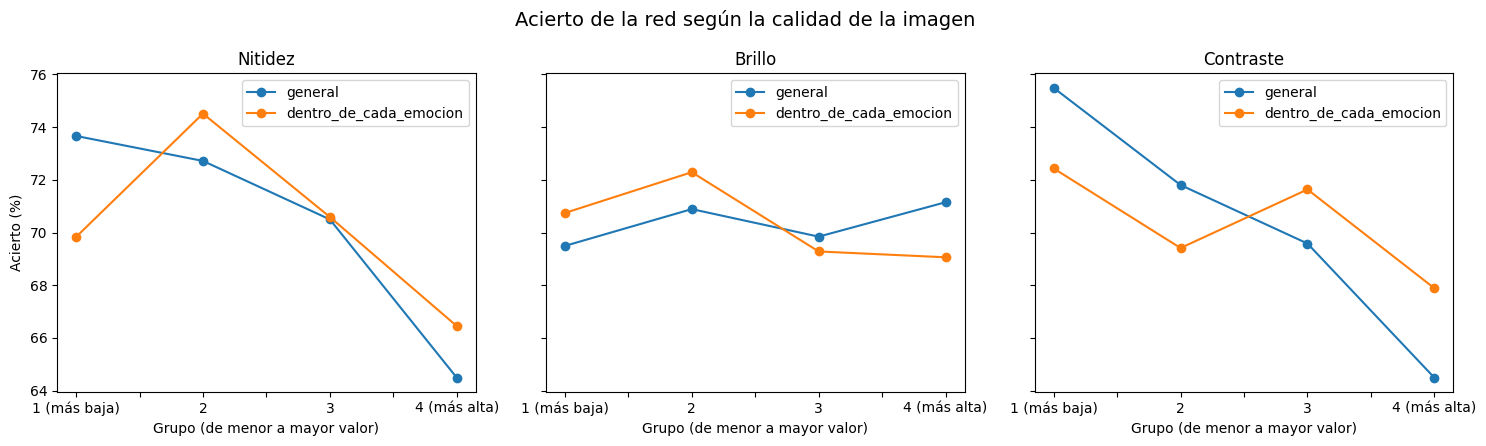

In [2]:
# Compara el acierto de la red según la nitidez, el brillo y el contraste, en general y dentro de cada emoción.
medidas = ["nitidez", "brillo", "contraste"]
resultados = {}

for medida in medidas:
    general = pd.qcut(df[medida], 4, labels=False)
    dentro = df.groupby("emocion")[medida].transform(lambda s: pd.qcut(s, 4, labels=False))
    resultados[medida] = pd.DataFrame({
        "general": df.groupby(general)["acierto"].mean() * 100,
        "dentro_de_cada_emocion": df.groupby(dentro)["acierto"].mean() * 100,
    })
    resultados[medida].index = ["1 (más baja)", "2", "3", "4 (más alta)"]
    print(f"--- Acierto (%) según {medida} ---")
    display(resultados[medida].round(1))

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for eje, medida in zip(ejes, medidas):
    resultados[medida].plot(marker="o", ax=eje)
    eje.set_title(medida.capitalize())
    eje.set_xlabel("Grupo (de menor a mayor valor)")
    eje.set_ylabel("Acierto (%)")

plt.suptitle("Acierto de la red según la calidad de la imagen", fontsize=14)
plt.tight_layout()
plt.savefig(GRAFICOS / "06_acierto_vs_calidad.png", dpi=150)
plt.show()

In [3]:
# Compara el acierto en imágenes en blanco y negro contra las de color, y guarda las tablas del notebook para Power BI.
color = df.assign(tipo=df["es_gris"].map({True: "Blanco y negro", False: "Color"}))

general = color.groupby("tipo")["acierto"].agg(imagenes="count", acierto="mean")
general["acierto"] = (general["acierto"] * 100).round(1)
print(general)

por_emocion = color.pivot_table(index="emocion", columns="tipo", values="acierto", aggfunc=["mean", "count"])
tabla = pd.DataFrame({
    "acierto_color_%": (por_emocion["mean"]["Color"] * 100).round(1),
    "acierto_gris_%": (por_emocion["mean"]["Blanco y negro"] * 100).round(1),
    "imagenes_color": por_emocion["count"]["Color"],
    "imagenes_gris": por_emocion["count"]["Blanco y negro"],
})
tabla = tabla.loc[["Felicidad", "Neutral", "Tristeza", "Sorpresa", "Asco", "Enojo", "Miedo"]]
display(tabla)

tablas = []
for medida in ["nitidez", "brillo", "contraste"]:
    t = resultados[medida].round(1).reset_index().rename(columns={"index": "grupo"})
    t.insert(0, "medida", medida)
    tablas.append(t)
pd.concat(tablas).to_csv(RESULTADOS / "acierto_por_calidad.csv", index=False, encoding="utf-8-sig")
tabla.to_csv(RESULTADOS / "acierto_gris_color.csv", encoding="utf-8-sig")

                imagenes  acierto
tipo                             
Blanco y negro       479     63.7
Color               2586     71.6


,acierto_color_%,acierto_gris_%,imagenes_color,imagenes_gris
emocion,,,,
Felicidad,87.4,80.8,1081,104
Neutral,52.4,38.5,550,130
Tristeza,69.5,74.8,354,123
Sorpresa,72.0,72.0,304,25
Asco,56.9,53.3,130,30
Enojo,57.5,66.7,127,33
Miedo,15.0,67.6,40,34


In [4]:
# Revisa cuántas imágenes que no son de miedo clasificó la red como miedo, según sean grises o de color.
color["predijo_miedo"] = color["prediccion"] == "Miedo"
falsos = color[color["emocion"] != "Miedo"].groupby("tipo")["predijo_miedo"].agg(imagenes="count", dijo_miedo="sum")
falsos["porcentaje"] = (falsos["dijo_miedo"] / falsos["imagenes"] * 100).round(1)

print("Imágenes que NO son de miedo y la red clasificó como miedo:")
print(falsos)

Imágenes que NO son de miedo y la red clasificó como miedo:
                imagenes  dijo_miedo  porcentaje
tipo                                            
Blanco y negro       445          11         2.5
Color               2546          22         0.9
